# Statistical Analysis | Washington Housing Analysis

In [10]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

In [11]:
from pathlib import Path

DATA_DIR = Path('../data')

final_dataset_path = DATA_DIR / 'housing_final.csv'

df = pd.read_csv(final_dataset_path  , dtype = {'county_fips': str})

## Relationship between Home Value and Median Income

### Research Question
Is median household income significantly associated with county-level home values in Washington State?

$H_0$: The regression coefficient for median household income equals zero $(\beta_1 = 0)$.

$H_A$: The regression coefficient for median household income does not equal zero $(\beta_1 \ne 0)$.

### Method
Oridnary Least Squares (OLS)

We first fit the original model in dollars (Model 1), then correct three problems:

1. **Non-independent observations.** Each county appears 10 times (once per year), so rows are not independent and standard OLS p-values are too small. We use standard errors **clustered by county**.
2. **Errors grow with home value.** We model `log(home value)` on `log(income)`, so the coefficient is an elasticity (percent change in value for a 1% change in income) and the errors are more even.
3. **Differences between counties.** Income and home values both differ a lot between counties for reasons we do not measure. A model with county fixed effects (Model 3) looks at changes within each county over time.



### Model 1: Simple Linear Regression

In [18]:
import statsmodels.formula.api as smf
from statsmodels.stats.stattools import durbin_watson

model_df = df.dropna(subset=["average_zhvi", "median_income"]).copy()
model_1 = smf.ols("average_zhvi ~ median_income",data=model_df).fit()

print(model_1.summary())

                            OLS Regression Results                            
Dep. Variable:           average_zhvi   R-squared:                       0.712
Model:                            OLS   Adj. R-squared:                  0.711
Method:                 Least Squares   F-statistic:                     956.2
Date:                Sun, 22 Nov 2026   Prob (F-statistic):          1.28e-106
Time:                        14:16:30   Log-Likelihood:                -4942.1
No. Observations:                 389   AIC:                             9888.
Df Residuals:                     387   BIC:                             9896.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept     -1.754e+05   1.71e+04    -10.241

* The p-value is less than our significance level of 0.05 hence we reject $H_0$.
* The regression coefficient ($\beta_1$) for median household income is 8.1776.
* A `$10,000` Dollar increase in household income explains approximately `$81,776` increase in home value.
* The $R^2$ value of 0.712 indicates that the median income explains approximately 71.2% of the observed variations in the given home values.
* **Problem:** the Durbin-Watson statistic is about 0.27 (values near 2 are healthy), which signals strong autocorrelation. The same counties repeat every year, so the p-value above is overstated. Model 2 corrects this.

Review actual vs predicted home value

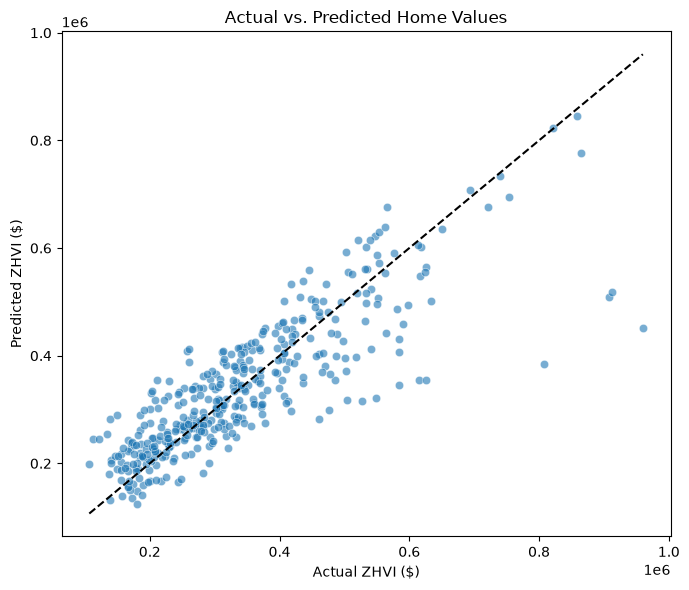

In [13]:
model_df["predicted_zhvi"] = model_1.predict(model_df)

plt.figure(figsize=(7, 6))

sns.scatterplot(
    data=model_df,
    x="average_zhvi",
    y="predicted_zhvi",
    alpha=0.6
)

min_val = min(model_df["average_zhvi"].min(), model_df["predicted_zhvi"].min())
max_val = max(model_df["average_zhvi"].max(), model_df["predicted_zhvi"].max())

plt.plot([min_val, max_val], [min_val, max_val], "k--")

plt.title("Actual vs. Predicted Home Values")
plt.xlabel("Actual ZHVI ($)")
plt.ylabel("Predicted ZHVI ($)")
plt.tight_layout()
plt.show()

* The actual-versus-predicted plot suggests that the model captures the general relationship between median household income and home values.
* Predictions are relatively close to actual values for many lower-valued observations.
* Prediction errors appear to increase as actual home values rise.
* The model substantially underestimates some higher-valued homes.

Resudual by regions

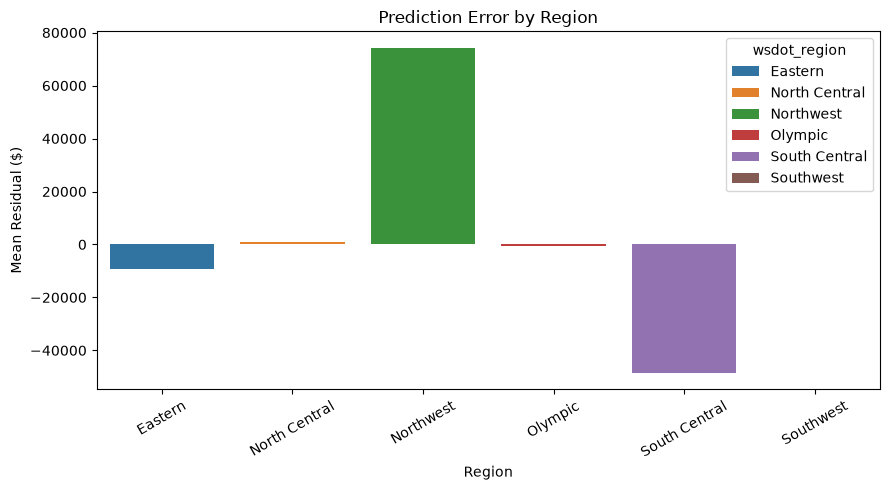

In [14]:
model_df["residual"] = (model_df["average_zhvi"] - model_df["predicted_zhvi"])

regional_residuals = (model_df.groupby("wsdot_region", as_index=False).agg(mean_residual=("residual", "mean")))

plt.figure(figsize=(9, 5))

sns.barplot(
    data=regional_residuals,
    x="wsdot_region",
    y="mean_residual",
    hue="wsdot_region",
    legend=True
)

plt.title("Prediction Error by Region")
plt.xlabel("Region")
plt.ylabel("Mean Residual ($)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

* Model underestimated home values in Northwest region by average of approximately `$75,000`.
* Model also oversetaimated home values in the South Central region by overage of approximately `$42,000`.
* Strong case for including regional calssification to the multiple regression model

### Model 2: Log-log model with county-clustered standard errors

In [21]:
model_df["log_zhvi"] = np.log(model_df["average_zhvi"])
model_df["log_income"] = np.log(model_df["median_income"])
print(model_df.shape)
model_2 = smf.ols("log_zhvi ~ log_income", data=model_df).fit(
    cov_type="cluster", cov_kwds={"groups": model_df["county_fips"]}
)
print(model_2.summary().tables[1])
print(f"\nR-squared: {model_2.rsquared:.3f} | residual SD (log): {np.sqrt(model_2.mse_resid):.3f}")

(389, 10)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -4.3247      0.914     -4.730      0.000      -6.117      -2.533
log_income     1.5397      0.082     18.666      0.000       1.378       1.701

R-squared: 0.723 | residual SD (log): 0.221


In [22]:
b = model_2.params["log_income"]; lo, hi = model_2.conf_int().loc["log_income"]
print(f"A 1% higher median income is associated with a {b:.2f}% higher home value (95% CI {lo:.2f}% to {hi:.2f}%)")
print(f"Doubling income (+100%) is associated with a {(2 ** b - 1) * 100:.0f}% higher home value")

A 1% higher median income is associated with a 1.54% higher home value (95% CI 1.38% to 1.70%)
Doubling income (+100%) is associated with a 191% higher home value


* We still reject $H_0$ at the 0.05 level (cluster-robust p-value), so income is associated with home values. The standard errors now account for repeated observations from the same county. (They are not comparable with Model 1's, because the two models use different units.)
* The coefficient is an elasticity: a 1% higher income is associated with roughly a 1.5% higher home value. This compares counties of different sizes on a percentage basis.
* This is an association, not proof that income causes higher home values. Counties with higher incomes differ in many other ways.

### Model 3: Adding county fixed effects

In [23]:

model_3 = smf.ols("log_zhvi ~ log_income + C(county_fips)", data=model_df).fit(
    cov_type="cluster", cov_kwds={"groups": model_df["county_fips"]}
)
print(f"log_income coefficient: {model_3.params['log_income']:.3f} (SE {model_3.bse['log_income']:.3f}, p = {model_3.pvalues['log_income']:.4f})")
print(f"R-squared: {model_3.rsquared:.3f} | residual SD (log): {np.sqrt(model_3.mse_resid):.3f}")

# Autocorrelation of residuals within each county (near 2 is healthy)
for name, m in [("Model 2", model_2), ("Model 3", model_3)]:
    dw = pd.Series(m.resid.values, index=model_df.index).groupby(model_df["county_fips"]).apply(lambda s: durbin_watson(s.values)).mean()
    print(f"{name}: mean within-county Durbin-Watson = {dw:.2f}")

log_income coefficient: 1.681 (SE 0.050, p = 0.0000)
R-squared: 0.961 | residual SD (log): 0.087
Model 2: mean within-county Durbin-Watson = 0.32
Model 3: mean within-county Durbin-Watson = 0.78


* With county fixed effects, the coefficient measures how a county's home values move when its own income changes over time, and not differences between counties.
* The coefficient (about 1.68) is close to Model 2 (about 1.54), so the relationship also holds within counties over time. Because both income and home values trend upward and are in nominal dollars, part of this still reflects the shared time trend (notebook 04 tests this by adding year effects).
* The Durbin-Watson values show whether autocorrelation remains. Values well below 2 mean residuals from one year still predict the next, so even clustered standard errors deserve some caution.

### Compare all Three Models

In [24]:
compare = pd.DataFrame({
    "Model 1: dollars, OLS": {"income coef": f"{model_1.params['median_income']:.3f}", "SE": f"{model_1.bse['median_income']:.3f}", "p": f"{model_1.pvalues['median_income']:.4f}", "R-squared": f"{model_1.rsquared:.3f}"},
    "Model 2: log-log, clustered": {"income coef": f"{model_2.params['log_income']:.3f}", "SE": f"{model_2.bse['log_income']:.3f}", "p": f"{model_2.pvalues['log_income']:.4f}", "R-squared": f"{model_2.rsquared:.3f}"},
    "Model 3: + county FE": {"income coef": f"{model_3.params['log_income']:.3f}", "SE": f"{model_3.bse['log_income']:.3f}", "p": f"{model_3.pvalues['log_income']:.4f}", "R-squared": f"{model_3.rsquared:.3f}"},
})
compare

,"Model 1: dollars, OLS","Model 2: log-log, clustered",Model 3: + county FE
income coef,8.178,1.540,1.681
SE,0.264,0.082,0.050
p,0.0000,0.0000,0.0000
R-squared,0.712,0.723,0.961


* All three regression models show a positive and sitatistically significant association between median househole income and county-level home values.
* Initial OLS model produced an $R^2$ value of 0.712,
* Log-log model with county clustered SE produced $R^2$ of 0.723, and after accounting for county fixed effects, the model produced an $R^2$ value of 0.961.
* Overall, consistent evidence of a politive relationship between income and home value. 

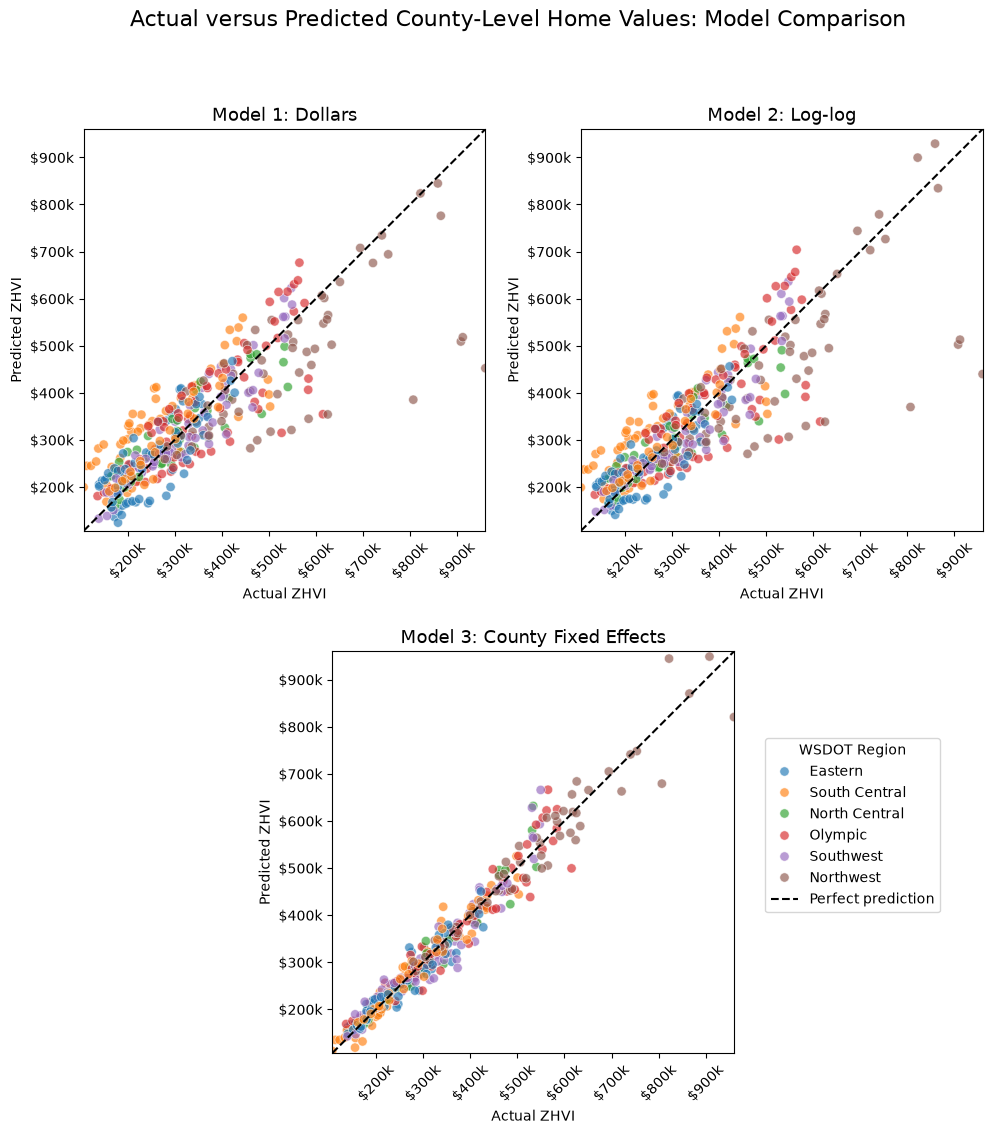

In [53]:
from matplotlib.gridspec import GridSpec
from matplotlib.ticker import FuncFormatter

money_fmt = FuncFormatter(lambda x, pos: f"${x/1000:,.0f}k")

fig = plt.figure(figsize=(12, 12))

gs = GridSpec(2, 4, figure=fig, hspace=0.30,wspace=0.35)

axes = [
    fig.add_subplot(gs[0, 0:2]),
    fig.add_subplot(gs[0, 2:4]),
    fig.add_subplot(gs[1, 1:3])
]

axis_min = model_df["average_zhvi"].min()
axis_max = model_df["average_zhvi"].max()

models = [
    ("pred_m1", "Model 1: Dollars"),
    ("pred_m2", "Model 2: Log-log"),
    ("pred_m3", "Model 3: County Fixed Effects")
]

for ax, (col, title) in zip(axes, models):

    sns.scatterplot(
        data=model_df,
        x="average_zhvi",
        y=col,
        hue="wsdot_region",
        alpha=0.65,
        s=45,
        ax=ax,
        legend=(ax is axes[0])
    )

    ax.plot([axis_min, axis_max],[axis_min, axis_max], "k--", label="Perfect prediction")

    ax.set_xlim(axis_min, axis_max)
    ax.set_ylim(axis_min, axis_max)
    ax.set_aspect("equal", adjustable="box")

    ax.set_title(title, fontsize=13)
    ax.set_xlabel("Actual ZHVI")
    ax.set_ylabel("Predicted ZHVI")
    
    ax.tick_params(axis="x", labelrotation=45)
    
    ax.xaxis.set_major_formatter(money_fmt)
    ax.yaxis.set_major_formatter(money_fmt)

# Put legend outside the figure
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(handles, labels, title="WSDOT Region", loc="center left",bbox_to_anchor=(0.7, 0.3))

# Remove legend inside first plot
axes[0].get_legend().remove()

fig.suptitle("Actual versus Predicted County-Level Home Values: Model Comparison", fontsize=16,)

plt.show()

* Both Models 1 and 2 does well capturing relationship between median household income and home value. However prediction errors for high-value home value oversvations persists, especially in the Northwest region.
* Model 3 incorporates county fixed effects, fitted values closer to actual home values. 

### Visualize and Compare Residuals

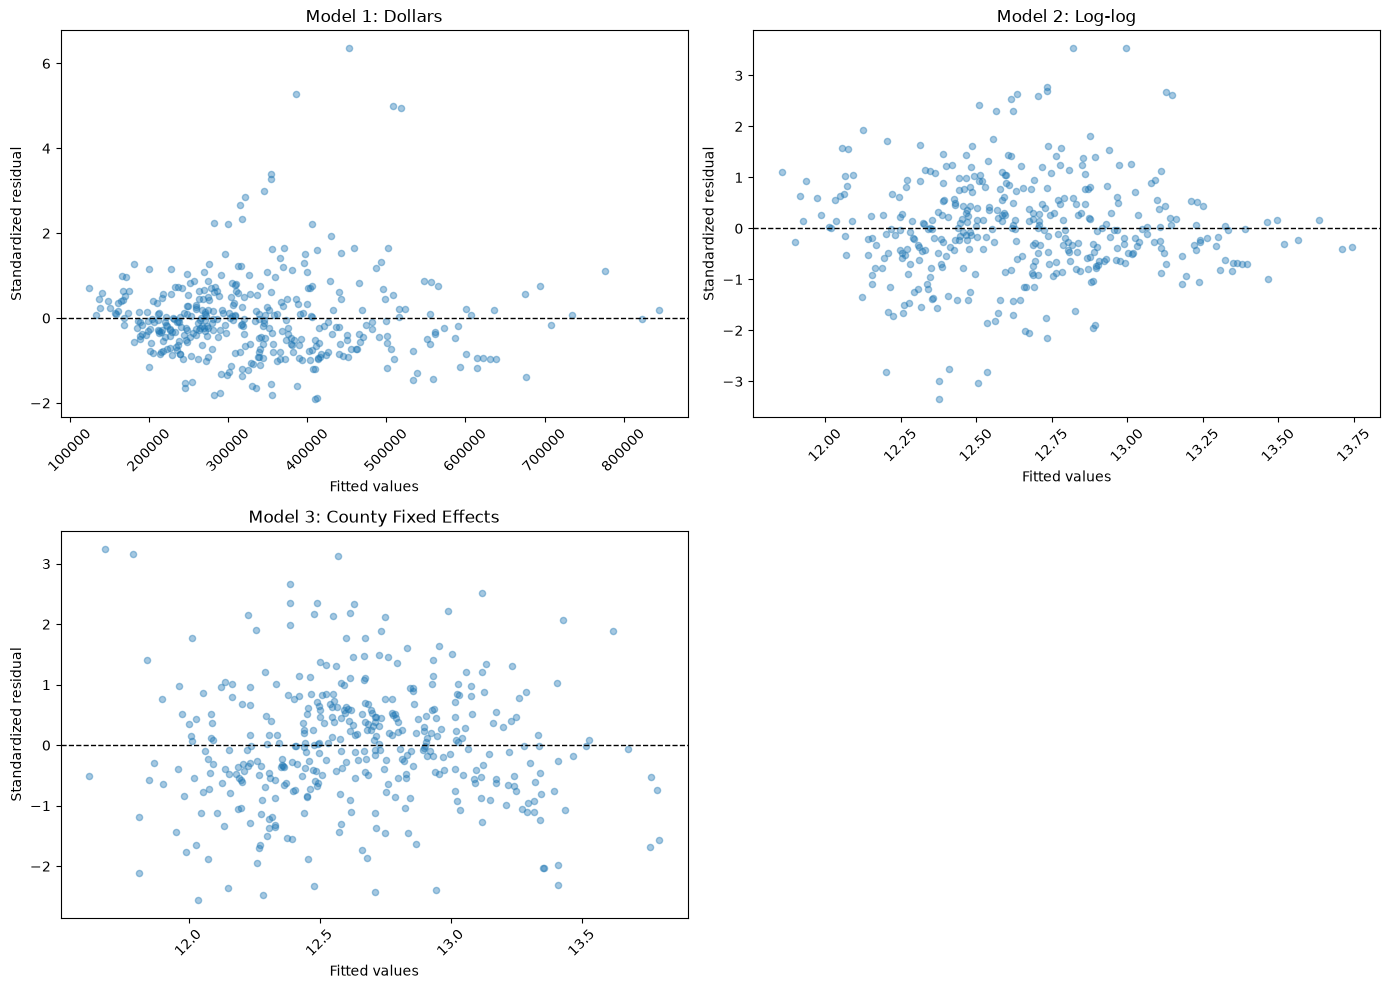

In [57]:
fig, axes = plt.subplots(2,2,figsize= (14,10))
axes = axes.flatten()

resid_info = [
    (model_1.fittedvalues, model_1.resid / model_1.resid.std(), "Model 1: Dollars"),
    (model_2.fittedvalues, model_2.resid /model_2.resid.std(), "Model 2: Log-log"),
    (model_3.fittedvalues, model_3.resid / model_3.resid.std(), "Model 3: County Fixed Effects")
]

for ax, (x, y, title) in zip(axes, resid_info):
    ax.scatter(x, y, alpha = 0.4, s = 20)
    ax.axhline(y=0, color = "black", linestyle= "--", linewidth = 1)
    ax.set_title(title)
    ax.set_xlabel("Fitted values")
    ax.set_ylabel("Standardized residual")
    ax.tick_params(axis="x", labelrotation=45)
    
axes[3].axis("off")

plt.tight_layout()
plt.show()

* Model 1 shows uneven dispersion in residuals. Specially around home values between 350,000 and 550,000.
* Model 2 shows residuals are balanced around zero, suggesting imporovement in residual behavior.
* Visual inspection of the standardized residuals does not reveal a substantial improvement in residual patterns compared with Model 2.
* Model 3 did  achieves a considerably higher $R^2$ (0.961 versus 0.723), suggesting county fixed effects account for additional variation in home values.

## Model 4: County plus Year effects
Does income remain assiciated with county-level home value after accounting for both county and year effects?

In [58]:
model_4 = smf.ols("log_zhvi ~ log_income + C(county_fips) + C(year)", data=model_df).fit(
    cov_type="cluster", cov_kwds={"groups": model_df["county_fips"]}
)

In [62]:
print(f"log_income coefficient: {model_4.params['log_income']:.3f} (SE {model_4.bse['log_income']:.3f}, p = {model_4.pvalues['log_income']:.4f})")
print(f"R-squared: {model_4.rsquared:.3f} | residual SD (log): {np.sqrt(model_4.mse_resid):.3f}")


log_income coefficient: 0.067 (SE 0.150, p = 0.6563)
R-squared: 0.991 | residual SD (log): 0.041


After extending Model 3 and including year fixed effects, the estimated coefficient for the log median household income decreased from 1.681 to 0.067. The p-value of 0.6563 suggest that the median household income was not statistically significant and we fail to reject null hypothesis at the 0.05 significance level.


Compare All Four Models

In [63]:
compare = pd.DataFrame({
    "Model 1: dollars, OLS": {"income coef": f"{model_1.params['median_income']:.3f}", "SE": f"{model_1.bse['median_income']:.3f}", "p": f"{model_1.pvalues['median_income']:.4f}", "R-squared": f"{model_1.rsquared:.3f}"},
    "Model 2: log-log, clustered": {"income coef": f"{model_2.params['log_income']:.3f}", "SE": f"{model_2.bse['log_income']:.3f}", "p": f"{model_2.pvalues['log_income']:.4f}", "R-squared": f"{model_2.rsquared:.3f}"},
    "Model 3: + county FE": {"income coef": f"{model_3.params['log_income']:.3f}", "SE": f"{model_3.bse['log_income']:.3f}", "p": f"{model_3.pvalues['log_income']:.4f}", "R-squared": f"{model_3.rsquared:.3f}"},
    "Model 4: + county FE + year FE": {"income coef": f"{model_4.params['log_income']:.3f}", "SE": f"{model_4.bse['log_income']:.3f}", "p": f"{model_4.pvalues['log_income']:.4f}", "R-squared": f"{model_4.rsquared:.3f}"},
})
compare

,"Model 1: dollars, OLS","Model 2: log-log, clustered",Model 3: + county FE,Model 4: + county FE + year FE
income coef,8.178,1.540,1.681,0.067
SE,0.264,0.082,0.050,0.150
p,0.0000,0.0000,0.0000,0.6563
R-squared,0.712,0.723,0.961,0.991


* Models 1 - 3 show positive and statistically significant association between median household income and home value.
* Income coefficient decreases to 0.067 and with the p-value of 0.6563, median income is no longer statistically significant.
* Strong income assiciation observed in Models 1-3 may have been influenced by other factors and shared trends.


## RQ1: Summary 
### Key Findings
1. **Model 1 - Simple Linear Regression:** The initial OLS model identified a statistically significant politive relationship between median household income and zillow home value index (ZHVI). A `$10,000` higher median income was associated with approxiately `$81,776` higher ZHVI. The model acheived $R^2$ value of 0.712, indicating income accounted for approximately 71.2% of overrved vairation in home value.
2. **Model 2 - log-log Regression:** After log transformation and using county-clustered standard errors, the relationship between median household income and ZHVI remained statistically significant. With the income coefficient of 1.54, 1% increase in higher median household income was associated with approximately 1.54% increase in home values.
3. **Model 3 - County Fixed Effects:** After accounting for differences between counties, the income coefficient marginally increased to 1.681. Additionally, relationship between ZHVI and income remained statistically significant.
4. **Model 4 - County and Year Fixed Effects:** We then included year fixed effects in addition to county fixed effects, allowing the model to account for common annual trends affecting all counties in Washington State. The income coefficient decreased considerably to 0.067 and was no longer statistically significant (p = 0.6563). Although the model achieved an $R^2$ of 0.991, this reflects the explanatory power of the full model, including county and year effects, rather than income alone.
### Conclusion
Although Median household income showed a strong positive relation with home values in the initial linear regression models, after accounting for county differences and shared annual trends, the relationship became considerable weaker and statistically insignificant.

These results suggest that geographic differences and broader housing-market trends may play an important role in explaining variations in home values across Washington State.

To answer our original research question, we found a statistically significant positive association between median household income and home values in the simpler models. However, after accounting for county and year fixed effects, we did not find sufficient statistical evidence of an additional association between income and home values.